# fisherNN v3 — frozen closed-form bodies for class-incremental learning

v2 settled the gauge question: the signed-permutation symmetry is exact, but aligning re-solves does
nothing for accuracy, and **freezing the body after task 0 matched the offline body** (0.727 vs
0.722) at a cost of 4–8 points vs backprop. v3 drops the gauge grid and asks three questions:

1. **Is "frozen ≈ offline" real?** 3 seeds of offline FD / frozen task-0 FD / frozen random bodies.
2. **When does freezing fail?** Fit the frozen body on deliberately poor data: 1 class, 200 images,
   grayscale, or a different dataset (SVHN); then run class-incremental CIFAR-10 on it.
3. **How much does a better readout recover?** Concatenate L2+L3 and add a RanPAC-style random
   ReLU expansion before the exact ridge readout, on FD and random bodies alike.
Plus fair backprop references: **joint** training (upper bound), **finetune**, and **replay**
(class-balanced buffer).

**Protocol notes**
- 5,000 training images are held out as a validation set. The ridge λ is chosen per step from a grid on
  validation accuracy over the classes seen so far (the usual hyper-parameter convention for CL
  benchmarks). Training uses the other 45,000, so numbers sit slightly below v2's.
- Bodies are frozen after their fit, so each readout is exact: its final accuracy equals a joint ridge
  fit on the same features. Every body is evaluated with all readouts in one shared feature pass.
- Results are also written to `results_v3.json`.

Set `SMOKE = True` for a few-minute run on synthetic data before the real one.

In [1]:
import math, copy, time, gc, json
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F

try:                                    # same SSL fix as v1, harmless if certifi is missing
    import ssl, certifi
    ssl._create_default_https_context = lambda: ssl.create_default_context(cafile=certifi.where())
except ImportError:
    pass

SMOKE = False
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
BETA = 0.1                              # S_W += BETA * S_T
POOL = 4
STAT_DEV = 'cpu'                        # ridge statistics + solves in float64 here; GPU extracts features
TASKS = [(0, 1), (2, 3), (4, 5), (6, 7), (8, 9)]
LAMS = (1e-3, 1e-2, 1e-1, 1.0)          # ridge grid; chosen per step on validation

if SMOKE:
    WIDTHS, CNN_WIDTHS, RP_DIM, VAL_N = (8, 16, 32), (16, 32, 64), 512, 300
    SEEDS, STRESS_SEEDS = (0, 1), (0,)
    BP_EPOCHS, JOINT_EPOCHS, REPLAY_PER_CLASS = 1, 2, 20
    STRESS_SMALL_N = 50
else:
    WIDTHS, CNN_WIDTHS, RP_DIM, VAL_N = (32, 64, 128), (64, 128, 256), 8192, 5000
    SEEDS, STRESS_SEEDS = (0, 1, 2), (0,)
    BP_EPOCHS, JOINT_EPOCHS, REPLAY_PER_CLASS = 5, 15, 200   # replay buffer = 2,000 images at the end
    STRESS_SMALL_N = 200

RUN = dict(main=True, stress=True, bp=True)
OUT = dict(main={}, stress={}, bp={}, config=dict(widths=WIDTHS, rp_dim=RP_DIM, lams=LAMS, val_n=VAL_N,
                                                  seeds=SEEDS, beta=BETA, smoke=SMOKE))

## Data and augmentation

In [2]:
def load_cifar(root='./data'):
    import torchvision
    tr = torchvision.datasets.CIFAR10(root, train=True, download=True)
    te = torchvision.datasets.CIFAR10(root, train=False, download=True)
    f = lambda d: torch.tensor(d.data).permute(0, 3, 1, 2).float() / 255
    Xtr, Xte = f(tr), f(te)
    mean, std = Xtr.mean((0, 2, 3), keepdim=True), Xtr.std((0, 2, 3), keepdim=True)
    return (Xtr - mean) / std, torch.tensor(tr.targets), (Xte - mean) / std, torch.tensor(te.targets)

def load_svhn(n=10000, root='./data'):
    """SVHN training images normalized by their own statistics (the domain-shift body)."""
    import torchvision
    d = torchvision.datasets.SVHN(root, split='train', download=True)
    X = torch.tensor(d.data[:n]).float() / 255
    return (X - X.mean((0, 2, 3), keepdim=True)) / X.std((0, 2, 3), keepdim=True)

def load_synthetic(n_tr=2000, n_te=600, seed=0):
    """10 classes of smooth colour templates + structured noise + shifts. For code checks only."""
    g = torch.Generator().manual_seed(seed)
    T = F.interpolate(torch.randn(10, 3, 4, 4, generator=g), size=32, mode='bicubic', align_corners=False)
    def make(n):
        y = torch.randint(0, 10, (n,), generator=g)
        x = (T[y] * (0.5 + torch.rand(n, 1, 1, 1, generator=g))
             + 1.5 * F.interpolate(torch.randn(n, 3, 8, 8, generator=g), size=32, mode='bilinear',
                                   align_corners=False)
             + 0.5 * torch.randn(n, 3, 32, 32, generator=g))
        s = torch.randint(-3, 4, (n, 2), generator=g)
        return torch.stack([torch.roll(x[i], tuple(s[i].tolist()), (1, 2)) for i in range(n)]), y
    Xtr, Ytr = make(n_tr); Xte, Yte = make(n_te)
    mean, std = Xtr.mean((0, 2, 3), keepdim=True), Xtr.std((0, 2, 3), keepdim=True)
    return (Xtr - mean) / std, Ytr, (Xte - mean) / std, Yte

def augment(x):
    """v1 augmentation: photometric + a shared 1-px roll per call (two calls -> relative shift)."""
    B = x.shape[0]
    x = x * (1 + 0.4 * (torch.rand(B, 1, 1, 1, device=x.device) - 0.5))
    x = x + 0.3 * torch.randn(B, 3, 1, 1, device=x.device)
    x = x + 0.1 * torch.randn_like(x)
    dy, dx = torch.randint(-1, 2, (2,)).tolist()
    return torch.roll(x, (dy, dx), (2, 3))

pool = lambda h: F.adaptive_avg_pool2d(h, POOL).flatten(1)

Xall, Yall, Xte, Yte = load_synthetic() if SMOKE else load_cifar()
_perm = torch.randperm(len(Xall), generator=torch.Generator().manual_seed(1234))
Xva, Yva = Xall[_perm[:VAL_N]], Yall[_perm[:VAL_N]]
Xtr, Ytr = Xall[_perm[VAL_N:]], Yall[_perm[VAL_N:]]
del Xall, Yall

def task_data(cls):
    m = torch.isin(Ytr, torch.tensor(cls)); return Xtr[m], Ytr[m]

print(f'device {dev} | train {tuple(Xtr.shape)} | val {tuple(Xva.shape)} | test {tuple(Xte.shape)} '
      f'| smoke={SMOKE}')

def free(tag=None):
    gc.collect()
    if torch.cuda.is_available():
        if tag: print(f'    [{tag}: peak GPU {torch.cuda.max_memory_allocated() / 2**30:.2f} GiB]')
        torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()

Files already downloaded and verified
Files already downloaded and verified
device cuda | train (45000, 3, 32, 32) | val (5000, 3, 32, 32) | test (10000, 3, 32, 32) | smoke=False


## Fisher-discriminant layers (v2's stable solver, gauge code removed)

In [3]:
@torch.no_grad()
def gen_eig(ST, SW, k):
    """Top-k solutions of S_T w = λ S_W w. float64 on CPU; whitening via eigh(S_W)."""
    ST, SW = ST.double().cpu(), SW.double().cpu()
    s, V = torch.linalg.eigh((SW + SW.T) / 2)
    s = s.clamp_min(s.max() * 1e-12)
    Linv = (V / s.sqrt()).T
    M = Linv @ ST @ Linv.T
    lam, U = torch.linalg.eigh((M + M.T) / 2)
    return lam.flip(0)[:k], Linv.T @ U.flip(1)[:, :k]

class FDLayer:
    def __init__(self, in_ch, k, ks, beta=BETA, eps=1e-3):
        self.ks, self.d = ks, in_ch * ks * ks
        self.k, self.beta, self.eps = min(k, self.d), beta, eps
        z = lambda *s: torch.zeros(*s, dtype=torch.float64, device=dev)
        self.n, self.s1, self.s2, self.nw, self.sw = 0.0, z(self.d), z(self.d, self.d), 0.0, z(self.d, self.d)
        self.W = self.mu = None

    def patches(self, x):
        return F.unfold(x, self.ks, padding=self.ks // 2)

    @torch.no_grad()
    def observe(self, xa, xb, n_pos=64):
        pa, pb = self.patches(xa), self.patches(xb)
        idx = torch.randint(0, pa.shape[2], (n_pos,), device=dev)
        pa = pa[:, :, idx].transpose(1, 2).reshape(-1, self.d)
        pb = pb[:, :, idx].transpose(1, 2).reshape(-1, self.d)
        P, D = torch.cat([pa, pb]), pa - pb
        self.n += P.shape[0];  self.s1 += P.sum(0).double(); self.s2 += (P.T @ P).double()
        self.nw += D.shape[0]; self.sw += (D.T @ D).double()

    @torch.no_grad()
    def solve(self, random=False):
        mu = self.s1 / self.n
        ST = self.s2 / self.n - torch.outer(mu, mu)
        SW = self.sw / self.nw + self.beta * ST
        SW = SW + self.eps * SW.trace() / self.d * torch.eye(self.d, dtype=SW.dtype, device=dev)
        if random:
            W = torch.randn(self.d, self.k, dtype=torch.float64) / self.d ** 0.5
        else:
            _, W = gen_eig(ST, SW, self.k)
        self.mu, self.W = mu.float(), W.float().to(dev)

    def forward(self, x):
        B, _, H, Wd = x.shape
        z = torch.einsum('bdl,dk->bkl', self.patches(x) - self.mu[None, :, None], self.W)
        z = z.reshape(B, self.k, H, Wd)
        return F.avg_pool2d(torch.cat([F.relu(z), F.relu(-z)], 1), 2)

class FDNet:
    def __init__(self, widths=WIDTHS, beta=BETA):
        k1, k2, k3 = widths
        self.layers = [FDLayer(3, k1, 5, beta), FDLayer(2 * k1, k2, 3, beta), FDLayer(2 * k2, k3, 3, beta)]
    def run(self, x, upto):
        for l in self.layers[:upto]: x = l.forward(x)
        return x
    def feats(self, x):
        outs = []
        for l in self.layers: x = l.forward(x); outs.append(x)
        return outs

@torch.no_grad()
def fit_layers(net, X, bs=256, random=False, epochs=1):
    """Greedy, layer by layer. `epochs` > 1 re-uses the same images under fresh augmentations."""
    for i, layer in enumerate(net.layers):
        for _ in range(epochs):
            for idx in torch.randperm(len(X)).split(bs):
                x = X[idx].to(dev)
                layer.observe(net.run(augment(x), i), net.run(augment(x), i))
        layer.solve(random)

def make_body(X, seed, random=False, epochs=1, widths=WIDTHS):
    torch.manual_seed(seed)
    net = FDNet(widths); fit_layers(net, X, random=random, epochs=epochs)
    return net

## Readouts: feature maps and an exact multi-λ ridge

A `FeatureMap` picks layers, standardizes each block with statistics from task-0 images (available at
task 0, then frozen) and optionally applies a fixed random projection + ReLU (RanPAC-style).
`RidgeReadout` keeps v2's numerically robust statistics and solves every λ in `LAMS` at each step.

In [4]:
class FeatureMap:
    def __init__(self, layers=(3,), rp_dim=0, seed=0):
        self.layers, self.rp_dim, self.seed = layers, rp_dim, seed
    @torch.no_grad()
    def fit(self, net, X, n=5000, bs=500):
        X = X[:n]
        blocks = [[] for _ in self.layers]
        for i in range(0, len(X), bs):
            fs = net.feats(X[i:i + bs].to(dev))
            for b, l in zip(blocks, self.layers): b.append(pool(fs[l - 1]))
        blocks = [torch.cat(b) for b in blocks]
        self.mu = [b.mean(0) for b in blocks]
        self.sd = [b.std(0).clamp_min(1e-6 * b.std(0).mean() + 1e-12) for b in blocks]
        d = sum(b.shape[1] for b in blocks)
        if self.rp_dim:
            g = torch.Generator().manual_seed(10_000 + self.seed)
            self.R = (torch.randn(d, self.rp_dim, generator=g) / d ** 0.5).to(dev)
        return self
    def __call__(self, fs):
        z = torch.cat([(pool(fs[l - 1]) - m) / s for l, m, s in zip(self.layers, self.mu, self.sd)], 1)
        return F.relu(z @ self.R) if self.rp_dim else z

READOUTS = {                       # name -> (layers, random-projection dim)
    'L3':           ((3,), 0),
    'L2+L3':        ((2, 3), 0),
    'RP(L3)':       ((3,), RP_DIM),
    'RP(L2+L3)':    ((2, 3), RP_DIM),
}

def spd_solve(C, B, lam):
    """Solve (C + lam I) X = B for symmetric PSD C; C is restored afterwards. Jitter on failure."""
    jitter = 0.0
    for _ in range(6):
        shift = lam + jitter
        C.diagonal().add_(shift)
        L, info = torch.linalg.cholesky_ex(C)
        C.diagonal().sub_(shift)
        if info.item() == 0:
            if jitter: print(f'    [spd_solve: extra jitter {jitter:.1e}]')
            return torch.cholesky_solve(B, L)
        jitter = max(10 * jitter, 1e-6)
    e, V = torch.linalg.eigh(C)
    return V @ ((V.T @ B) / (e.clamp_min(0) + lam)[:, None])

class RidgeReadout:
    """Exact RLS readout. Features are buffered on the GPU and folded into a shifted Gram matrix in
    chunks; statistics and solves are float64 on STAT_DEV (see v2 for why)."""
    def __init__(self, d, c=10, buf_mb=128):
        z = lambda *s: torch.zeros(*s, dtype=torch.float64, device=STAT_DEV)
        self.A, self.H, self.s, self.ys, self.n = z(d, d), z(d, c), z(d), z(c), 0.0
        self.c0, self.buf, self.nbuf = None, [], 0
        self.chunk = max(256, (buf_mb << 20) // (4 * d))
    def observe(self, phi, y):
        self.buf.append((phi.float(), y)); self.nbuf += len(phi)
        if self.nbuf >= self.chunk: self.flush()
    @torch.no_grad()
    def flush(self):
        if not self.buf: return
        phi = torch.cat([p for p, _ in self.buf]); y = torch.cat([q for _, q in self.buf])
        self.buf, self.nbuf = [], 0
        if self.c0 is None: self.c0 = phi.mean(0).double().to(STAT_DEV)
        phi = phi - self.c0.to(phi.device, torch.float32)
        Y = F.one_hot(y, self.H.shape[1]).float()
        to = lambda t: t.to(STAT_DEV, torch.float64)
        self.A += to(phi.T @ phi); self.H += to(phi.T @ Y)
        self.s += to(phi.sum(0));  self.ys += to(Y.sum(0)); self.n += len(phi)
    @torch.no_grad()
    def solve(self, lams=LAMS, var_floor=1e-6):
        self.flush()
        m, yb = self.s / self.n, self.ys / self.n
        C = self.A / self.n
        C -= torch.outer(m, m)
        C += C.T.clone(); C /= 2
        var = C.diagonal().clone()
        sd = var.clamp_min(var_floor * var.clamp_min(0).mean() + 1e-12).sqrt()
        C /= sd[:, None]; C /= sd[None, :]
        Hc = (self.H / self.n - torch.outer(m, yb)) / sd[:, None]
        Ws = torch.stack([spd_solve(C, Hc, lam) / sd[:, None] for lam in lams])   # (L, d, c)
        del C
        bs = yb[None] - torch.einsum('d,ldc->lc', m + self.c0, Ws)
        self.W, self.b = Ws.float().to(dev), bs.float().to(dev)
    def predict(self, phi):                     # (L, B, c): one set of logits per λ
        return torch.einsum('bd,ldc->lbc', phi, self.W) + self.b[:, None]

## Class-incremental harness for a frozen body
One pass over each task feeds every readout; after each task all readouts are solved for every λ,
λ is picked on validation (seen classes), and test accuracy is reported at that λ.

In [5]:
@torch.no_grad()
def eval_readouts(net, fmaps, heads, X, Y, seen, bs=500):
    """Accuracy per readout per λ on images of seen classes: dict name -> (acc_all[L], acc_task0[L])."""
    m = torch.isin(Y, torch.tensor(seen)); X, Y = X[m], Y[m]
    t0 = torch.isin(Y, torch.tensor(TASKS[0]))
    mask = torch.full((10,), float('-inf'), device=dev); mask[seen] = 0
    hits = {k: [torch.zeros(len(LAMS)), torch.zeros(len(LAMS))] for k in fmaps}
    for i in range(0, len(X), bs):
        fs = net.feats(X[i:i + bs].to(dev)); y = Y[i:i + bs].to(dev); tm = t0[i:i + bs].to(dev)
        for k, fm in fmaps.items():
            ok = ((heads[k].predict(fm(fs)) + mask).argmax(2) == y).float()     # (L, B)
            hits[k][0] += ok.sum(1).cpu(); hits[k][1] += ok[:, tm].sum(1).cpu()
    n0 = max(1, t0.sum().item())
    return {k: (h[0] / len(X), h[1] / n0) for k, h in hits.items()}

@torch.no_grad()
def run_frozen_ci(net, readouts=READOUTS, fmap_X=None, seed=0, tag='', verbose=True):
    fmap_X = task_data(TASKS[0])[0] if fmap_X is None else fmap_X
    fmaps = {k: FeatureMap(l, r, seed).fit(net, fmap_X) for k, (l, r) in readouts.items()}
    heads, hist, seen = {k: None for k in fmaps}, {k: [] for k in fmaps}, []
    for t, cls in enumerate(TASKS):
        seen += list(cls); X, Y = task_data(cls)
        for i in range(0, len(X), 500):
            fs = net.feats(X[i:i + 500].to(dev)); y = Y[i:i + 500].to(dev)
            for k, fm in fmaps.items():
                phi = fm(fs)
                heads[k] = heads[k] or RidgeReadout(phi.shape[1]); heads[k].observe(phi, y)
        for h in heads.values(): h.solve()
        va = eval_readouts(net, fmaps, heads, Xva, Yva, seen)
        te = eval_readouts(net, fmaps, heads, Xte, Yte, seen)
        for k in fmaps:
            j = int(va[k][0].argmax())
            hist[k].append(dict(all=te[k][0][j].item(), task0=te[k][1][j].item(),
                                val=va[k][0][j].item(), lam=LAMS[j]))
        if verbose:
            print(f'  [{tag}] task {t}: ' + ' | '.join(f'{k} {hist[k][-1]["all"]:.3f}' for k in fmaps),
                  flush=True)
    del heads, fmaps
    return hist

def summarize(h):
    return dict(final=h[-1]['all'], task0=h[-1]['task0'], avg_inc=float(np.mean([r['all'] for r in h])),
                lam=h[-1]['lam'], curve=[r['all'] for r in h])

def mean_std(xs):
    a = np.array(xs, dtype=float); return a.mean(), (a.std(ddof=1) if len(a) > 1 else 0.0)

## Exp 1 — Seeds × bodies × readouts
Bodies: **offline FD** (fit on all 45k training images), **frozen FD** (fit on task 0 only), **frozen
random** (random filters, same architecture). Each body is evaluated with all four readouts.

In [6]:
BODIES = {
    'offline FD':  dict(data=lambda: Xtr, random=False),
    'frozen FD':   dict(data=lambda: task_data(TASKS[0])[0], random=False),
    'frozen rand': dict(data=lambda: task_data(TASKS[0])[0], random=True),
}

if RUN['main']:
    t0 = time.time()
    for body, spec in BODIES.items():
        for seed in SEEDS:
            ts = time.time()
            net = make_body(spec['data'](), seed, spec['random'])
            hist = run_frozen_ci(net, seed=seed, tag=f'{body} s{seed}')
            for k, h in hist.items():
                OUT['main'].setdefault(body, {}).setdefault(k, []).append(summarize(h))
            net = None; free(f'{body} seed {seed}: {time.time() - ts:.0f}s')
    print(f'[{time.time() - t0:.0f}s]\n')

    print(f'{"body":12s} {"readout":11s} {"final all":>15s} {"final task0":>15s} {"avg inc":>15s}  λ chosen')
    for body, d in OUT['main'].items():
        for k, runs in d.items():
            cell = lambda key: '%.3f ± %.3f' % mean_std([r[key] for r in runs])
            print(f'{body:12s} {k:11s} {cell("final"):>15s} {cell("task0"):>15s} {cell("avg_inc"):>15s}  '
                  f'{[r["lam"] for r in runs]}')

    [spd_solve: extra jitter 1.0e-02]
    [spd_solve: extra jitter 1.0e-02]
  [offline FD s0] task 0: L3 0.957 | L2+L3 0.957 | RP(L3) 0.956 | RP(L2+L3) 0.956
    [spd_solve: extra jitter 1.0e-02]
  [offline FD s0] task 1: L3 0.840 | L2+L3 0.849 | RP(L3) 0.834 | RP(L2+L3) 0.828
    [spd_solve: extra jitter 1.0e-02]
    [spd_solve: extra jitter 1.0e-02]
  [offline FD s0] task 2: L3 0.736 | L2+L3 0.745 | RP(L3) 0.728 | RP(L2+L3) 0.732
    [spd_solve: extra jitter 1.0e-02]
    [spd_solve: extra jitter 1.0e-02]
  [offline FD s0] task 3: L3 0.722 | L2+L3 0.731 | RP(L3) 0.706 | RP(L2+L3) 0.716
    [spd_solve: extra jitter 1.0e-02]
    [spd_solve: extra jitter 1.0e-02]
  [offline FD s0] task 4: L3 0.716 | L2+L3 0.726 | RP(L3) 0.690 | RP(L2+L3) 0.707
    [offline FD seed 0: 739s: peak GPU 1.42 GiB]
    [spd_solve: extra jitter 1.0e-02]
    [spd_solve: extra jitter 1.0e-02]
  [offline FD s1] task 0: L3 0.951 | L2+L3 0.947 | RP(L3) 0.949 | RP(L2+L3) 0.939
  [offline FD s1] task 1: L3 0.848 | L2+L

## Exp 2 — When does freezing fail?
The frozen body is fit on deliberately poor data, then class-incremental CIFAR-10 runs on top of it.
Every body sees about the same number of augmented pairs (`epochs = ceil(10k / n)`), so this measures
how many *distinct* images and how much diversity the body needs. The task-0 standardizer for the
readout always uses CIFAR task-0 images (they are available at task 0 in any case).

In [7]:
def gray(X):
    return X.mean(1, keepdim=True).expand(-1, 3, -1, -1).contiguous()

def stress_sets():
    X0 = task_data(TASKS[0])[0]
    g = torch.Generator().manual_seed(7)
    sets = {
        'task 0 (2 classes)':          X0,
        'class 0 only':                Xtr[Ytr == 0],
        f'task 0, {STRESS_SMALL_N} images': X0[torch.randperm(len(X0), generator=g)[:STRESS_SMALL_N]],
        'task 0, grayscale':           gray(X0),
    }
    try:
        sets['SVHN (10k)'] = load_svhn(n=10000 if not SMOKE else 500)
    except Exception as e:
        print(f'SVHN unavailable, skipping: {type(e).__name__}: {str(e)[:80]}')
    return sets

STRESS_READOUTS = {k: READOUTS[k] for k in ('L3', 'RP(L2+L3)')}

if RUN['stress']:
    t0 = time.time()
    n_ref = len(task_data(TASKS[0])[0])
    for name, Xs in stress_sets().items():
        ep = max(1, math.ceil(n_ref / len(Xs)))
        for seed in STRESS_SEEDS:
            ts = time.time()
            net = make_body(Xs, seed, epochs=ep)
            hist = run_frozen_ci(net, STRESS_READOUTS, seed=seed, tag=f'{name} s{seed}', verbose=False)
            for k, h in hist.items():
                OUT['stress'].setdefault(name, {}).setdefault(k, []).append(summarize(h))
            net = None; free(f'{name} ({len(Xs)} imgs × {ep} epochs) seed {seed}: {time.time() - ts:.0f}s')
    print(f'[{time.time() - t0:.0f}s]\n')

    ref = OUT['main'].get('frozen rand', {})
    print(f'{"body fit on":26s} ' + ' '.join(f'{k + " final":>18s}' for k in STRESS_READOUTS))
    for name, d in OUT['stress'].items():
        print(f'{name:26s} ' + ' '.join('%18s' % ('%.3f' % mean_std([r['final'] for r in d[k]])[0])
                                         for k in STRESS_READOUTS))
    if ref:
        print(f'{"(frozen random filters)":26s} ' + ' '.join(
            '%18s' % ('%.3f' % mean_std([r['final'] for r in ref[k]])[0]) for k in STRESS_READOUTS))

SVHN unavailable, skipping: ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
    [spd_solve: extra jitter 1.0e-02]
    [spd_solve: extra jitter 1.0e-03]
    [spd_solve: extra jitter 1.0e-03]
    [spd_solve: extra jitter 1.0e-03]
    [spd_solve: extra jitter 1.0e-04]
    [task 0 (2 classes) (8997 imgs × 1 epochs) seed 0: 167s: peak GPU 1.12 GiB]
    [spd_solve: extra jitter 1.0e-02]
    [spd_solve: extra jitter 1.0e-02]
    [spd_solve: extra jitter 1.0e-02]
    [spd_solve: extra jitter 1.0e-02]
    [spd_solve: extra jitter 1.0e-02]
    [class 0 only (4504 imgs × 2 epochs) seed 0: 177s: peak GPU 1.12 GiB]
    [spd_solve: extra jitter 1.0e-02]
    [spd_solve: extra jitter 1.0e-03]
    [spd_solve: extra jitter 1.0e-02]
    [spd_solve: extra jitter 1.0e-02]
    [spd_solve: extra jitter 1.0e-02]
    [task 0, 200 images (200 imgs × 45 epochs) seed 0: 258s: peak GPU 1.12 GiB]
    [spd_solve: extra jitter 1.0e-02]
    [spd_solve: extra jitter 

## Exp 3 — Backprop references: joint, finetune, replay
Same CNN as v2 (avg-pool, BN, widths `CNN_WIDTHS`). Replay keeps a class-balanced buffer of
`REPLAY_PER_CLASS` images per seen class and trains on current task ∪ buffer. EWC is dropped: in v2 it
behaved like finetuning, the known result for class-incremental learning.

In [8]:
class CNN(nn.Module):
    def __init__(self, w=CNN_WIDTHS):
        super().__init__()
        blk = lambda i, o, k: nn.Sequential(nn.Conv2d(i, o, k, padding=k // 2), nn.BatchNorm2d(o),
                                            nn.ReLU(), nn.AvgPool2d(2))
        self.body = nn.Sequential(blk(3, w[0], 5), blk(w[0], w[1], 3), blk(w[1], w[2], 3))
        self.head = nn.Linear(w[2] * 16, 10)
    def forward(self, x): return self.head(self.body(x).flatten(1))

def train(model, X, Y, epochs, bs=128, lr=1e-3):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs * math.ceil(len(X) / bs))
    model.train()
    for _ in range(epochs):
        for idx in torch.randperm(len(X)).split(bs):
            loss = F.cross_entropy(model(augment(X[idx].to(dev))), Y[idx].to(dev))
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    model.eval()

@torch.no_grad()
def acc_seen(model, seen):
    m = torch.isin(Yte, torch.tensor(seen)); X, Y = Xte[m], Yte[m]
    t0 = torch.isin(Y, torch.tensor(TASKS[0]))
    mask = torch.full((10,), float('-inf'), device=dev); mask[seen] = 0
    pred = torch.cat([(model(X[i:i + 500].to(dev)) + mask).argmax(1).cpu() for i in range(0, len(X), 500)])
    ok = (pred == Y).float()
    return ok.mean().item(), ok[t0].mean().item()

def ci_bp(per_class, epochs=BP_EPOCHS, seed=0, tag=''):
    torch.manual_seed(seed)
    model, bufX, bufY, seen, hist = CNN().to(dev), Xtr[:0], Ytr[:0], [], []
    for t, cls in enumerate(TASKS):
        seen += list(cls); X, Y = task_data(cls)
        train(model, torch.cat([X, bufX]), torch.cat([Y, bufY]), epochs)
        if per_class:
            g = torch.Generator().manual_seed(seed * 100 + t)
            for c in cls:
                Xc = X[Y == c]; sel = torch.randperm(len(Xc), generator=g)[:per_class]
                bufX, bufY = torch.cat([bufX, Xc[sel]]), torch.cat([bufY, torch.full((len(sel),), c)])
        a, a0 = acc_seen(model, seen)
        hist.append(dict(all=a, task0=a0))
        print(f'  [{tag}] task {t}: all {a:.3f} | task0 {a0:.3f}', flush=True)
    return hist

if RUN['bp']:
    t0 = time.time()
    torch.manual_seed(0)
    joint = CNN().to(dev); train(joint, Xtr, Ytr, JOINT_EPOCHS)
    OUT['bp']['joint (upper bound)'] = dict(final=acc_seen(joint, list(range(10)))[0])
    print(f'  [joint BP] {JOINT_EPOCHS} epochs: test {OUT["bp"]["joint (upper bound)"]["final"]:.3f}')
    del joint; free('joint')
    for name, per_class in (('BP finetune', 0), (f'BP replay {REPLAY_PER_CLASS}/class', REPLAY_PER_CLASS)):
        OUT['bp'][name] = summarize([dict(r, lam=None) for r in ci_bp(per_class, tag=name)])
        free(name)
    print(f'[{time.time() - t0:.0f}s]')

  [joint BP] 15 epochs: test 0.824
    [joint: peak GPU 0.27 GiB]
  [BP finetune] task 0: all 0.954 | task0 0.954
  [BP finetune] task 1: all 0.417 | task0 0.000
  [BP finetune] task 2: all 0.273 | task0 0.000
  [BP finetune] task 3: all 0.225 | task0 0.000
  [BP finetune] task 4: all 0.171 | task0 0.000
    [BP finetune: peak GPU 0.27 GiB]
  [BP replay 200/class] task 0: all 0.954 | task0 0.954
  [BP replay 200/class] task 1: all 0.612 | task0 0.421
  [BP replay 200/class] task 2: all 0.377 | task0 0.312
  [BP replay 200/class] task 3: all 0.390 | task0 0.539
  [BP replay 200/class] task 4: all 0.320 | task0 0.045
    [BP replay 200/class: peak GPU 0.27 GiB]
[147s]


## Summary
Reading guide:
- **Q1** holds if `frozen FD` ≈ `offline FD` within seed spread for every readout.
- **Q2:** a stress body "fails" when it drops toward the frozen-random row.
- **Q3:** the gain of `RP(L2+L3)` over `L3` on the FD body vs on the random body says whether the
  expansion adds to the FD features or merely substitutes for them. Compare with `BP replay` and the
  joint upper bound.

method                                  final all  final t0  avg inc seeds
joint (upper bound)                  0.824                 —        —     1
offline FD · L2+L3                   0.728 ± 0.002     0.802    0.802     3
frozen FD · L2+L3                    0.721 ± 0.007     0.794    0.800     3
frozen FD · L3                       0.718 ± 0.006     0.791    0.796     3
offline FD · L3                      0.716 ± 0.001     0.788    0.794     3
offline FD · RP(L2+L3)               0.704 ± 0.008     0.779    0.785     3
frozen FD · RP(L2+L3)                0.703 ± 0.017     0.780    0.787     3
frozen FD · RP(L3)                   0.699 ± 0.021     0.780    0.781     3
offline FD · RP(L3)                  0.694 ± 0.009     0.772    0.782     3
frozen rand · L2+L3                  0.631 ± 0.004     0.715    0.736     3
frozen rand · L3                     0.624 ± 0.005     0.715    0.730     3
frozen rand · RP(L2+L3)              0.615 ± 0.004     0.708    0.726     3
frozen rand ·

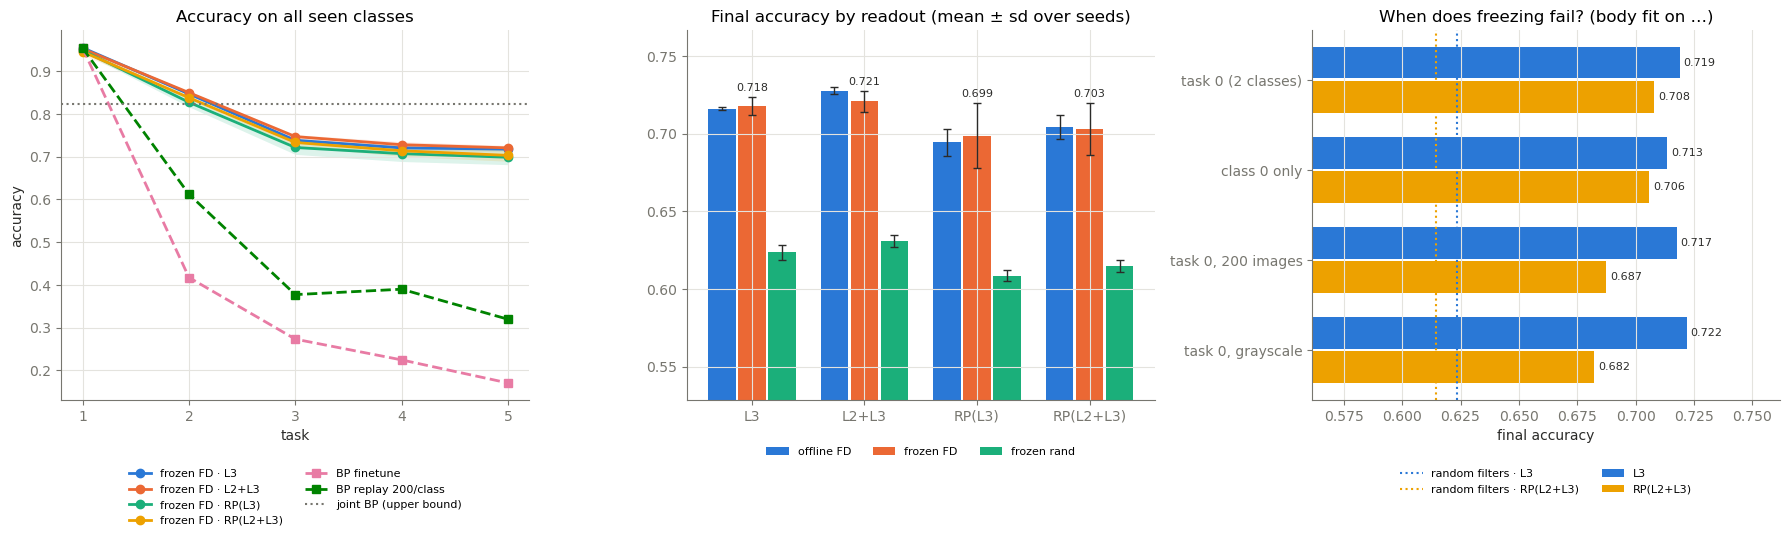

saved results_v3.json and summary_v3.png


In [9]:
import matplotlib.pyplot as plt

SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
INK, MUTED, GRID = '#2b2b29', '#77766f', '#e4e3de'
plt.rcParams.update({'axes.edgecolor': MUTED, 'axes.labelcolor': INK, 'xtick.color': MUTED,
                     'ytick.color': MUTED, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'font.size': 10})

rows = []
for body, d in OUT['main'].items():
    for k, runs in d.items():
        rows.append((f'{body} · {k}', *mean_std([r['final'] for r in runs]),
                     mean_std([r['task0'] for r in runs])[0], mean_std([r['avg_inc'] for r in runs])[0], len(runs)))
for name, r in OUT['bp'].items():
    rows.append((name, r['final'], 0.0, r.get('task0', float('nan')), r.get('avg_inc', float('nan')), 1))
print(f'{"method":32s} {"final all":>16s} {"final t0":>9s} {"avg inc":>8s} seeds')
f3 = lambda v: '%9.3f' % v if v == v else '%9s' % '—'
for name, m, s, t0_, ai, n in sorted(rows, key=lambda r: -r[1]):
    sd = f'± {s:.3f}' if n > 1 else ' ' * 7
    print(f'{name:32s} {m:9.3f} {sd} {f3(t0_)} {f3(ai)[1:]} {n:5d}')

fig, ax = plt.subplots(1, 3, figsize=(18, 5.6))
steps = np.arange(1, len(TASKS) + 1)

# (a) curves: frozen FD body, one line per readout; BP references in later slots
if 'frozen FD' in OUT['main']:
    for i, (k, runs) in enumerate(OUT['main']['frozen FD'].items()):
        C = np.array([r['curve'] for r in runs]); m, s = C.mean(0), C.std(0)
        ax[0].plot(steps, m, color=SERIES[i], lw=2, marker='o', ms=6, label=f'frozen FD · {k}')
        ax[0].fill_between(steps, m - s, m + s, color=SERIES[i], alpha=0.15, lw=0)
for j, name in enumerate([n for n in OUT['bp'] if 'curve' in OUT['bp'][n]]):
    ax[0].plot(steps, OUT['bp'][name]['curve'], color=SERIES[4 + j], lw=2, ls='--', marker='s', ms=6,
               label=name)
if 'joint (upper bound)' in OUT['bp']:
    ax[0].axhline(OUT['bp']['joint (upper bound)']['final'], color=MUTED, lw=1.5, ls=':',
                  label='joint BP (upper bound)')
ax[0].set(title='Accuracy on all seen classes', xlabel='task', ylabel='accuracy', xticks=steps)
ax[0].legend(fontsize=8, frameon=False, ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.16))

# (b) final accuracy: readouts on x, one bar per body
bodies = list(OUT['main'])
if bodies:
    ks = list(READOUTS); x = np.arange(len(ks)); w = 0.8 / len(bodies)
    for i, body in enumerate(bodies):
        ms = [mean_std([r['final'] for r in OUT['main'][body][k]]) for k in ks]
        bars = ax[1].bar(x + (i - (len(bodies) - 1) / 2) * w, [m for m, _ in ms], w * 0.92,
                         yerr=[s for _, s in ms], color=SERIES[i], label=body, capsize=3,
                         error_kw=dict(ecolor=INK, lw=1))
        if body == 'frozen FD':
            ax[1].bar_label(bars, fmt='%.3f', fontsize=8, color=INK, padding=3)
    lo = min(mean_std([r['final'] for r in OUT['main'][b][k]])[0] for b in bodies for k in ks)
    ax[1].set(title='Final accuracy by readout (mean ± sd over seeds)', xticks=x, xticklabels=ks,
              ylim=(max(0, lo - 0.08), None))
    ax[1].legend(fontsize=8, frameon=False, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.1))

# (c) stress: final accuracy of each stress body, frozen-random reference line
if OUT['stress']:
    names = list(OUT['stress']); y = np.arange(len(names)); ks = list(STRESS_READOUTS); h = 0.38
    for i, k in enumerate(ks):
        vals = [mean_std([r['final'] for r in OUT['stress'][n][k]])[0] for n in names]
        bars = ax[2].barh(y + (i - 0.5) * h, vals, h * 0.92, color=SERIES[i * 3], label=k)
        ax[2].bar_label(bars, fmt='%.3f', fontsize=8, color=INK, padding=3)
        if 'frozen rand' in OUT['main']:
            ax[2].axvline(mean_std([r['final'] for r in OUT['main']['frozen rand'][k]])[0],
                          color=SERIES[i * 3], lw=1.5, ls=':', label=f'random filters · {k}')
    allv = [r['final'] for n in names for k in ks for r in OUT['stress'][n][k]]
    if 'frozen rand' in OUT['main']:
        allv += [r['final'] for k in ks for r in OUT['main']['frozen rand'][k]]
    ax[2].set(title='When does freezing fail? (body fit on …)', yticks=y, yticklabels=names,
              xlabel='final accuracy', xlim=(max(0, min(allv) - 0.05), min(1.0, max(allv) + 0.04)))
    ax[2].invert_yaxis(); ax[2].grid(axis='y', visible=False)
    ax[2].legend(fontsize=8, frameon=False, ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.16))

fig.tight_layout(); fig.savefig('summary_v3.png', dpi=130)
plt.show()

with open('results_v3.json', 'w') as f:
    json.dump(OUT, f, indent=1, default=str)
print('saved results_v3.json and summary_v3.png')